# 03 — Semantic Distance Between Parties

Compare the average semantic content of health-related speeches across five source party categories: PD, FdI, M5S, Forza Italia and Lega. Reuse the speech embeddings from notebook 02; a CPU runtime is sufficient.

The three calendar periods are **2018–2019**, **2020** and **2021–2022**. The corpus covers only part of 2018 and 2022, and 2020 includes the months preceding the emergency. The final period is a later pandemic period, not a post-pandemic period.

The main selection uses BERTopic topic 0; the sensitivity check adds topic 14 (end-of-life discourse). These topic IDs refer to the saved run in notebook 02. Both selections are approximate.

Party labels are inherited from ItaParlCorpus and abbreviated during corpus preparation. They are not corrected for changes in parliamentary group and may differ from the affiliation stated in a speech. Results therefore compare the source party categories.

Profiles give equal weight to each speech. Cosine distances and hierarchical clusters describe similarity in the embedding space, not direct political agreement. Comparisons are descriptive and do not identify a causal effect of COVID-19.

**Inputs:** the prepared corpus, health selection and speech embeddings saved by notebooks 01 and 02.  
**Outputs:** `03_linguistic_analysis/outputs/`.

Run cells in order. Download the final archive before ending the Colab session; files under `/content` are temporary.

## 1. Load the health corpus and define the study groups

Download and cache the inputs from the project repository. Match speeches through their original identifiers throughout the analysis.


In [1]:
from pathlib import Path

import hashlib
import json
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests

PROJECT_DIR = Path("/content/italian-parliament-health-discourse")
OUTPUT_DIR = PROJECT_DIR / "03_linguistic_analysis/outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPOSITORY_URL = "https://github.com/MnGianmaria/Italian-parliament-health-discourse"
RAW_BASE = (
    "https://raw.githubusercontent.com/"
    "MnGianmaria/Italian-parliament-health-discourse/main/"
)
LFS_BASE = (
    "https://media.githubusercontent.com/media/"
    "MnGianmaria/Italian-parliament-health-discourse/main/"
)
INPUT_URLS = {
    "health": RAW_BASE + "02_health_identification/outputs/corpus_health_bertopic.parquet",
    "embeddings": LFS_BASE + "02_health_identification/outputs/speech_embeddings.npz",
    "prepared": LFS_BASE + "data/processed/corpus_prepared.parquet",
    "selection": RAW_BASE + "02_health_identification/outputs/bertopic_selection.parquet",
}
input_files = {}


def download_input(name, relative_path):
    """Reuse a local input, or download it atomically."""
    path = PROJECT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        temporary_path = path.with_suffix(path.suffix + ".part")
        with requests.get(INPUT_URLS[name], stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            with temporary_path.open("wb") as output:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output.write(chunk)
        temporary_path.replace(path)
    input_files[name] = path
    return path


health_path = download_input(
    "health", "02_health_identification/outputs/corpus_health_bertopic.parquet"
)
health_corpus = pd.read_parquet(health_path)

PARTIES = ["PD", "FdI", "M5S", "FI", "Lega"]
PERIODS = ["2018–2019", "2020", "2021–2022"]

study = health_corpus.loc[
    health_corpus["analysis_party"].isin(PARTIES)
].copy().reset_index(drop=True)

def assign_period(dates):
    return pd.cut(dates.dt.year, bins=[2017, 2019, 2020, 2022], labels=PERIODS)


study["period"] = assign_period(study["date_parsed"])

if study["row_id"].isna().any() or study["row_id"].duplicated().any():
    raise ValueError("Speech IDs must be non-missing and unique.")

if study["period"].isna().any():
    raise ValueError("Some speeches fall outside the study periods.")

speech_counts = pd.crosstab(
    study["analysis_party"],
    study["period"],
).reindex(index=PARTIES, columns=PERIODS, fill_value=0)

print(f"Main health corpus: {len(health_corpus):,}")
print(f"Five-party study sample: {len(study):,}")

display(speech_counts)


Main health corpus: 3,415
Five-party study sample: 2,400


period,2018–2019,2020,2021–2022
analysis_party,,,
PD,127,150,224
FdI,44,114,570
M5S,188,170,179
FI,81,103,169
Lega,43,94,144


## 2. Describe the party-period samples

Summarize the number of speeches, speakers and debate dates in each group. Report the largest speaker's share of speeches to describe concentration in contributions.

These summaries describe the observed sample; they do not establish that speeches are independent.


In [2]:
group_columns = ["analysis_party", "period"]
group_order = pd.MultiIndex.from_product(
    [PARTIES, PERIODS],
    names=group_columns,
)

sample_summary = (
    study.groupby(group_columns, observed=True)
    .agg(
        speeches=("row_id", "size"),
        speakers=("speaker", "nunique"),
        debate_dates=("date_parsed", "nunique"),
    )
    .reindex(group_order)
)

speaker_counts = (
    study.groupby(group_columns + ["speaker"], observed=True)
    .size()
)
largest_speaker_count = speaker_counts.groupby(
    level=group_columns, observed=True
).max()

sample_summary["largest_speaker_share"] = (
    largest_speaker_count / sample_summary["speeches"]
)

sample_summary.to_csv(OUTPUT_DIR / "sample_composition.csv")

display(
    sample_summary.assign(
        largest_speaker_share=sample_summary["largest_speaker_share"].map("{:.1%}".format)
    )
)


speeches  speakers  debate_dates  \
analysis_party period                                        
PD             2018–2019       127        44            53   
               2020            150        38            59   
               2021–2022       224        49            84   
FdI            2018–2019        44        15            29   
               2020            114        26            57   
               2021–2022       570        36            97   
M5S            2018–2019       188        56            85   
               2020            170        58            81   
               2021–2022       179        49           103   
FI             2018–2019        81        26            46   
               2020            103        34            55   
               2021–2022       169        39            92   
Lega           2018–2019        43        27            35   
               2020             94        40            57   
               2021–2022       144        46            77   

                         largest_speaker_share  
analysis_party period                           
PD             2018–2019                 14.2%  
               2020                      12.7%  
               2021–2022                 12.9%  
FdI            2018–2019                 18.2%  
               2020                      14.0%  
               2021–2022                 11.4%  
M5S            2018–2019                 13.8%  
               2020                      10.6%  
               2021–2022                 12.3%  
FI             2018–2019                 13.6%  
               2020                      11.7%  
               2021–2022                 15.4%  
Lega           2018–2019                  9.3%  
               2020                      11.7%  
               2021–2022                 13.2%

## 3. Load and align speech embeddings

Download the speech embeddings generated in notebook 02 and match them to the study sample using `row_id`.

Preserve the study sample's row order. Check that identifiers are unique, every study speech has an embedding, and vectors contain valid values.

No embedding model is loaded or rerun.

In [3]:
EMBEDDINGS_PATH = download_input(
    "embeddings", "02_health_identification/outputs/speech_embeddings.npz"
)

with np.load(EMBEDDINGS_PATH, allow_pickle=False) as saved:
    embedding_ids = pd.Index(saved["row_ids"].astype(str))
    all_embeddings = saved["embeddings"]
    embedding_model_name = str(saved["model_name"].item())

if embedding_ids.hasnans or not embedding_ids.is_unique:
    raise ValueError("Embedding IDs must be non-missing and unique.")

if all_embeddings.ndim != 2 or len(all_embeddings) != len(embedding_ids):
    raise ValueError("Embedding dimensions do not match the identifiers.")

if not np.isfinite(all_embeddings).all() or not np.allclose(
    np.linalg.norm(all_embeddings, axis=1), 1.0, atol=1e-5
):
    raise ValueError("All speech embeddings must be finite unit vectors.")

positions = embedding_ids.get_indexer(
    study["row_id"].to_numpy(dtype=str)
)

if (positions < 0).any():
    raise ValueError("Some study speeches have no matching embedding.")

study_embeddings = all_embeddings[positions].astype(np.float64)

print("Embedding model:", embedding_model_name)
print(f"Aligned speech embeddings: {study_embeddings.shape}")


Embedding model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Aligned speech embeddings: (2400, 384)


## 4. Construct party-period semantic profiles

Compute the mean speech embedding for each party-period group, giving equal weight to every speech. Normalize each mean vector to obtain the group's semantic profile.

Measure internal dispersion as the mean cosine distance between the speech vectors and their group's normalized profile.

These profiles summarize average semantic content. They may conceal differences between subtopics and do not directly represent political positions.

In [4]:
def make_profiles(frame, vectors):
    """Normalize the equally weighted mean speech vector in each group."""
    means = []
    for party, period in group_order:
        mask = (frame["analysis_party"].eq(party) & frame["period"].eq(period)).to_numpy()
        if not mask.any():
            raise ValueError(f"No speeches found for {party}, {period}.")
        means.append(vectors[mask].mean(axis=0))
    means = np.vstack(means)
    lengths = np.linalg.norm(means, axis=1)
    if not np.isfinite(lengths).all() or (lengths <= 1e-12).any():
        raise ValueError("A group has an invalid mean embedding.")
    return means / lengths[:, None], lengths


profiles, mean_lengths = make_profiles(study, study_embeddings)
semantic_profiles = pd.DataFrame(
    profiles,
    index=group_order,
    columns=[f"dimension_{i:03d}" for i in range(study_embeddings.shape[1])],
)

# For unit speech vectors, this equals their mean cosine distance
# from the normalized group mean.
semantic_dispersion = sample_summary[
    ["speeches", "speakers", "debate_dates"]
].copy()

semantic_dispersion["mean_distance_to_centroid"] = (
    1 - mean_lengths
)

semantic_profiles.to_parquet(
    OUTPUT_DIR / "semantic_profiles.parquet"
)
semantic_dispersion.to_csv(
    OUTPUT_DIR / "semantic_dispersion.csv"
)

display(semantic_dispersion.round(3))


speeches  speakers  debate_dates  \
analysis_party period                                        
PD             2018–2019       127        44            53   
               2020            150        38            59   
               2021–2022       224        49            84   
FdI            2018–2019        44        15            29   
               2020            114        26            57   
               2021–2022       570        36            97   
M5S            2018–2019       188        56            85   
               2020            170        58            81   
               2021–2022       179        49           103   
FI             2018–2019        81        26            46   
               2020            103        34            55   
               2021–2022       169        39            92   
Lega           2018–2019        43        27            35   
               2020             94        40            57   
               2021–2022       144        46            77   

                          mean_distance_to_centroid  
analysis_party period                                
PD             2018–2019                      0.192  
               2020                           0.143  
               2021–2022                      0.148  
FdI            2018–2019                      0.202  
               2020                           0.167  
               2021–2022                      0.195  
M5S            2018–2019                      0.188  
               2020                           0.152  
               2021–2022                      0.148  
FI             2018–2019                      0.189  
               2020                           0.162  
               2021–2022                      0.175  
Lega           2018–2019                      0.220  
               2020                           0.154  
               2021–2022                      0.182

## 5. Compare semantic profiles

Calculate cosine distances between normalized party-period profiles.

Compare each pair of parties within a period and each party across periods. A distance of 0 indicates identical profile directions; larger values indicate greater separation in the embedding space.

These distances describe average semantic content, not agreement on political positions. Their stability is assessed subsequently through resampling.

In [5]:
from itertools import combinations


def profile_distance(group_a, group_b):
    """Cosine distance between two normalized semantic profiles."""
    vector_a = semantic_profiles.loc[group_a].to_numpy()
    vector_b = semantic_profiles.loc[group_b].to_numpy()

    return float(np.clip(1 - vector_a @ vector_b, 0, 2))


between_party_rows = []

for period in PERIODS:
    for party_a, party_b in combinations(PARTIES, 2):
        between_party_rows.append({
            "party_a": party_a,
            "party_b": party_b,
            "period": period,
            "cosine_distance": profile_distance(
                (party_a, period),
                (party_b, period),
            ),
        })

between_party_distances = pd.DataFrame(between_party_rows)

within_party_rows = []

for party in PARTIES:
    for period_a, period_b in combinations(PERIODS, 2):
        within_party_rows.append({
            "party": party,
            "period_a": period_a,
            "period_b": period_b,
            "cosine_distance": profile_distance(
                (party, period_a),
                (party, period_b),
            ),
        })

within_party_distances = pd.DataFrame(within_party_rows)

between_party_distances.to_csv(
    OUTPUT_DIR / "semantic_between_party_distances.csv",
    index=False,
)
within_party_distances.to_csv(
    OUTPUT_DIR / "semantic_within_party_distances.csv",
    index=False,
)

print("Semantic distances between parties:")
display(
    between_party_distances.pivot(
        index=["party_a", "party_b"],
        columns="period",
        values="cosine_distance",
    ).reindex(columns=PERIODS).round(4)
)

print("Semantic changes within each party:")
display(
    within_party_distances.pivot(
        index="party",
        columns=["period_a", "period_b"],
        values="cosine_distance",
    ).reindex(index=PARTIES).round(4)
)

Semantic distances between parties:


period           2018–2019    2020  2021–2022
party_a party_b                              
FI      Lega        0.0175  0.0074     0.0064
FdI     FI          0.0148  0.0075     0.0340
        Lega        0.0222  0.0095     0.0253
        M5S         0.0232  0.0224     0.0458
M5S     FI          0.0240  0.0163     0.0039
        Lega        0.0171  0.0222     0.0098
PD      FI          0.0061  0.0125     0.0052
        FdI         0.0156  0.0189     0.0334
        Lega        0.0180  0.0194     0.0083
        M5S         0.0292  0.0082     0.0057

Semantic changes within each party:


period_a 2018–2019                2020
period_b      2020 2021–2022 2021–2022
party                                 
PD          0.0318    0.0392    0.0141
FdI         0.0379    0.0633    0.0343
M5S         0.0324    0.0358    0.0115
FI          0.0217    0.0431    0.0246
Lega        0.0319    0.0313    0.0265

## 6. Visualize semantic groupings

Construct a hierarchical clustering of the five party profiles in each period using cosine distances and average linkage.

Use a common vertical scale across periods. The horizontal ordering has no ideological meaning. Groupings describe average semantic similarity and remain exploratory until their stability is assessed.

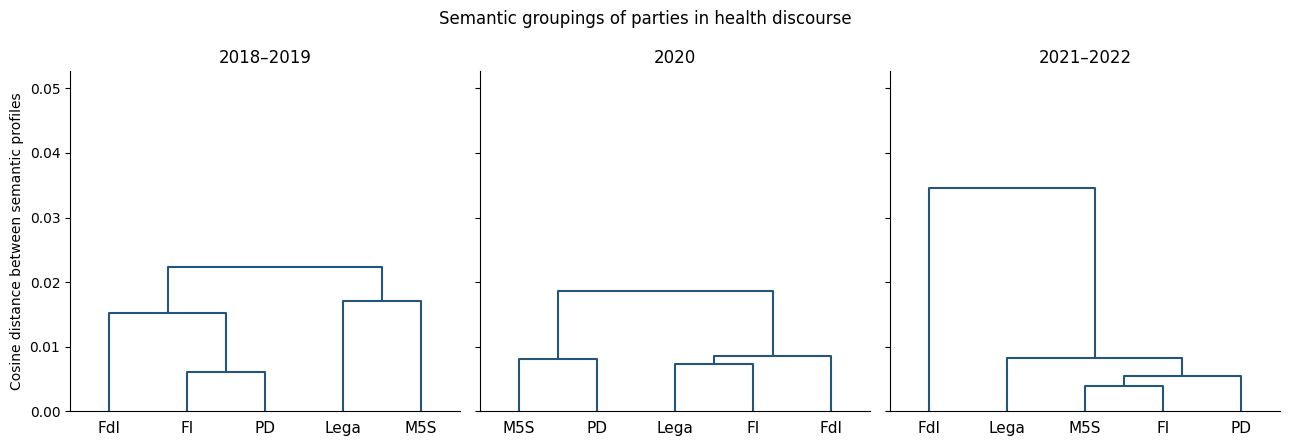

In [6]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

fig, axes = plt.subplots(
    1, len(PERIODS),
    figsize=(13, 4.5),
    sharey=True,
)

semantic_trees = {}
upper_limit = between_party_distances["cosine_distance"].max() * 1.15

for ax, period in zip(axes, PERIODS):
    distance_matrix = pd.DataFrame(
        0.0, index=PARTIES, columns=PARTIES
    )

    period_distances = between_party_distances.loc[
        between_party_distances["period"].eq(period)
    ]

    for row in period_distances.itertuples(index=False):
        distance_matrix.loc[row.party_a, row.party_b] = row.cosine_distance
        distance_matrix.loc[row.party_b, row.party_a] = row.cosine_distance

    tree = linkage(
        squareform(distance_matrix.to_numpy()),
        method="average",
        optimal_ordering=True,
    )
    semantic_trees[period] = tree

    dendrogram(
        tree,
        labels=PARTIES,
        ax=ax,
        color_threshold=0,
        above_threshold_color="#24557A",
        leaf_font_size=11,
    )

    ax.set_title(period)
    ax.set_ylim(0, upper_limit)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Cosine distance between semantic profiles")
fig.suptitle("Semantic groupings of parties in health discourse")
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        OUTPUT_DIR / f"semantic_party_dendrograms.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

## 7. Assess uncertainty through debate-date resampling

Resample debate dates with replacement within each period, using 500 repetitions and a fixed random seed. Retain all speeches from each selected date, including contributions from different parties.

Recompute the normalized party profiles and estimate changes in between-party distances from 2018–2019 to 2021–2022.

Negative changes indicate closer profiles; positive changes indicate greater separation. Percentile intervals provide an approximate assessment under date-level resampling. They do not account for dependence across dates, embedding-model error or errors in health-speech selection.
Intervals are pointwise 95% percentile intervals, without adjustment for the ten pairwise comparisons. Resampling is conditional on the saved model, source labels and selected speeches. Repeated speakers and serial dependence across dates are not explicitly modelled.


In [7]:
N_BOOTSTRAP = 500
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

group_positions = {
    group: position
    for position, group in enumerate(group_order)
}

bootstrap_profiles = np.empty(
    (N_BOOTSTRAP, len(group_order), study_embeddings.shape[1])
)

for period in PERIODS:
    mask = study["period"].eq(period).to_numpy()
    period_study = study.loc[mask]

    date_codes, dates = pd.factorize(period_study["date_parsed"])
    party_codes = pd.Index(PARTIES).get_indexer(
        period_study["analysis_party"]
    )

    # Sum speech vectors by date and party.
    date_vectors = np.zeros(
        (len(dates), len(PARTIES), study_embeddings.shape[1])
    )
    np.add.at(
        date_vectors,
        (date_codes, party_codes),
        study_embeddings[mask],
    )

    # Each row records how often each date is drawn.
    date_weights = rng.multinomial(
        len(dates),
        np.full(len(dates), 1 / len(dates)),
        size=N_BOOTSTRAP,
    )

    resampled_vectors = np.einsum(
        "bd,dpv->bpv",
        date_weights,
        date_vectors,
        optimize=True,
    )

    lengths = np.linalg.norm(
        resampled_vectors, axis=2, keepdims=True
    )

    if (lengths <= 1e-12).any():
        raise ValueError("A resampled group has no usable mean vector.")

    positions = [
        group_positions[(party, period)]
        for party in PARTIES
    ]

    # Normalizing sums gives the same directions as normalizing means.
    bootstrap_profiles[:, positions, :] = (
        resampled_vectors / lengths
    )

change_rows = []

for party_a, party_b in combinations(PARTIES, 2):
    sampled_distances = {}

    for period in [PERIODS[0], PERIODS[-1]]:
        vectors_a = bootstrap_profiles[
            :, group_positions[(party_a, period)], :
        ]
        vectors_b = bootstrap_profiles[
            :, group_positions[(party_b, period)], :
        ]

        sampled_distances[period] = np.clip(
            1 - np.sum(vectors_a * vectors_b, axis=1),
            0,
            2,
        )

    sampled_change = (
        sampled_distances[PERIODS[-1]]
        - sampled_distances[PERIODS[0]]
    )

    observed_change = (
        profile_distance(
            (party_a, PERIODS[-1]), (party_b, PERIODS[-1])
        )
        - profile_distance(
            (party_a, PERIODS[0]), (party_b, PERIODS[0])
        )
    )

    change_rows.append({
        "party_a": party_a,
        "party_b": party_b,
        "distance_change": observed_change,
        "bootstrap_p025": np.quantile(sampled_change, 0.025),
        "bootstrap_p975": np.quantile(sampled_change, 0.975),
    })

semantic_changes = pd.DataFrame(change_rows)

semantic_changes.to_csv(
    OUTPUT_DIR / "semantic_distance_changes.csv",
    index=False,
)

display(semantic_changes.round(4))


,party_a,party_b,distance_change,bootstrap_p025,bootstrap_p975
0,PD,FdI,0.0177,-0.0069,0.0258
1,PD,M5S,-0.0235,-0.0414,-0.0150
2,PD,FI,-0.0009,-0.0138,0.0023
3,PD,Lega,-0.0096,-0.0339,-0.0061
4,FdI,M5S,0.0226,-0.0067,0.0392
5,FdI,FI,0.0193,-0.0105,0.0341
6,FdI,Lega,0.0031,-0.0310,0.0110
7,M5S,FI,-0.0201,-0.0406,-0.0100
8,M5S,Lega,-0.0073,-0.0337,-0.0020
9,FI,Lega,-0.0111,-0.0377,-0.0058


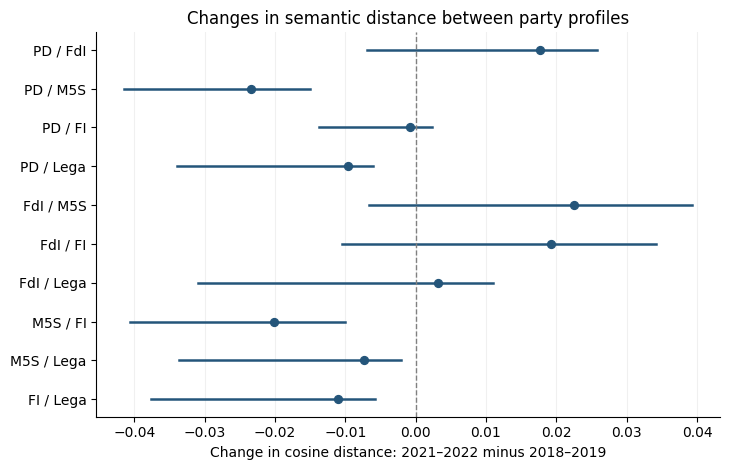

In [14]:
fig, ax = plt.subplots(figsize=(7.4, 4.8))

for i, row in enumerate(semantic_changes.itertuples(index=False)):
    ax.plot(
        [row.bootstrap_p025, row.bootstrap_p975],
        [i, i],
        color="#24557A",
        linewidth=1.8,
    )

ax.scatter(
    semantic_changes["distance_change"],
    range(len(semantic_changes)),
    color="#24557A",
    s=32,
    zorder=3,
)

ax.axvline(0, color="grey", linestyle="--", linewidth=1)

ax.set_yticks(
    range(len(semantic_changes)),
    semantic_changes["party_a"] + " / " + semantic_changes["party_b"],
)
ax.invert_yaxis()

ax.set_xlabel(
    "Change in cosine distance: 2021–2022 minus 2018–2019"
)
ax.set_title("Changes in semantic distance between party profiles")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

for extension in ["pdf", "png"]:
    fig.savefig(
        OUTPUT_DIR / f"semantic_distance_changes.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

## 8. Assess clustering stability

Rebuild the hierarchical clustering for each debate-date bootstrap sample.

Compare the two branches immediately below the final merge with the corresponding split in the observed dendrogram. Report how frequently the observed split is reproduced and how frequently FdI forms a branch on its own.

These frequencies describe stability under the specified resampling procedure; they are not probabilities that a grouping is correct.

In [8]:
from collections import Counter
from scipy.cluster.hierarchy import cut_tree


def root_partition(tree):
    """Canonical representation of the two branches below the root."""
    labels = cut_tree(tree, n_clusters=2).ravel()

    return tuple(sorted(
        tuple(sorted(
            party
            for party, label in zip(PARTIES, labels)
            if label == cluster
        ))
        for cluster in np.unique(labels)
    ))


stability_rows = []

for period in PERIODS:
    positions = [
        group_positions[(party, period)]
        for party in PARTIES
    ]

    partition_counts = Counter()

    for repetition in range(N_BOOTSTRAP):
        profiles = bootstrap_profiles[repetition, positions, :]

        distances = np.clip(1 - profiles @ profiles.T, 0, 2)
        np.fill_diagonal(distances, 0)

        tree = linkage(
            squareform(distances),
            method="average",
        )

        partition_counts[root_partition(tree)] += 1

    observed_partition = root_partition(semantic_trees[period])

    stability_rows.append({
        "period": period,
        "observed_split": " | ".join(
            " + ".join(branch)
            for branch in observed_partition
        ),
        "observed_split_frequency": (
            partition_counts[observed_partition] / N_BOOTSTRAP
        ),
        "fdi_separate_branch_frequency": (
            sum(
                count
                for partition, count in partition_counts.items()
                if ("FdI",) in partition
            ) / N_BOOTSTRAP
        ),
    })

cluster_stability = pd.DataFrame(stability_rows)

cluster_stability.to_csv(
    OUTPUT_DIR / "semantic_cluster_stability.csv",
    index=False,
)

display(cluster_stability.round(3))

,period,observed_split,observed_split_frequency,fdi_separate_branch_frequency
0,2018–2019,FI + FdI + PD | Lega + M5S,0.404,0.192
1,2020,FI + FdI + Lega | M5S + PD,0.964,0.004
2,2021–2022,FI + Lega + M5S + PD | FdI,0.998,0.998


## 9. Assess sensitivity to the health selection

Repeat the profile comparisons using the extended selection, including BERTopic topics 0 and 14.

Reuse the existing speech embeddings, party definitions and calendar periods. Compare distances and the two branches below the final dendrogram merge with those from the main selection.

This check assesses sensitivity to the inclusion of end-of-life discourse; it does not validate the health classification.

In [9]:
prepared_path = download_input("prepared", "data/processed/corpus_prepared.parquet")
selection_path = download_input(
    "selection", "02_health_identification/outputs/bertopic_selection.parquet"
)
prepared_metadata = pd.read_parquet(
    prepared_path, columns=["row_id", "analysis_party", "date_parsed"]
)
selection_flags = pd.read_parquet(selection_path)

extended_ids = selection_flags.loc[
    selection_flags["health_bertopic_extended"], ["row_id"]
]

extended_study = extended_ids.merge(
    prepared_metadata,
    on="row_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)
if extended_study["_merge"].ne("both").any():
    raise ValueError("Some extended IDs are absent from the prepared corpus.")
extended_study = extended_study.drop(columns="_merge")

extended_study = extended_study.loc[
    extended_study["analysis_party"].isin(PARTIES)
].copy()

extended_study["period"] = assign_period(extended_study["date_parsed"])
if not set(study["row_id"]).issubset(set(extended_study["row_id"])):
    raise ValueError("The extended selection must include the main sample.")

extended_positions = embedding_ids.get_indexer(
    extended_study["row_id"].to_numpy(dtype=str)
)

if (extended_positions < 0).any() or extended_study["period"].isna().any():
    raise ValueError("Extended records have missing embeddings or periods.")

extended_embeddings = all_embeddings[extended_positions].astype(np.float64)

extended_profiles, _ = make_profiles(extended_study, extended_embeddings)

extended_rows = []
selection_comparison = []

for period in PERIODS:
    positions = [
        group_positions[(party, period)]
        for party in PARTIES
    ]
    profiles = extended_profiles[positions]

    distances = np.clip(1 - profiles @ profiles.T, 0, 2)
    np.fill_diagonal(distances, 0)

    tree = linkage(squareform(distances), method="average")

    selection_comparison.append({
        "period": period,
        "main_split": root_partition(semantic_trees[period]),
        "extended_split": root_partition(tree),
        "same_split": (
            root_partition(semantic_trees[period])
            == root_partition(tree)
        ),
    })

    for i, j in combinations(range(len(PARTIES)), 2):
        extended_rows.append({
            "party_a": PARTIES[i],
            "party_b": PARTIES[j],
            "period": period,
            "extended_distance": distances[i, j],
        })

selection_sensitivity = between_party_distances.rename(
    columns={"cosine_distance": "main_distance"}
).merge(
    pd.DataFrame(extended_rows),
    on=["party_a", "party_b", "period"],
    validate="one_to_one",
)

selection_sensitivity.to_csv(
    OUTPUT_DIR / "semantic_selection_sensitivity.csv",
    index=False,
)

selection_cluster_comparison = pd.DataFrame(selection_comparison)
selection_cluster_comparison.to_csv(
    OUTPUT_DIR / "semantic_selection_cluster_comparison.csv",
    index=False,
)

print(f"Extended five-party sample: {len(extended_study):,}")
display(selection_cluster_comparison)


Extended five-party sample: 2,745


,period,main_split,extended_split,same_split
0,2018–2019,"((FI, FdI, PD), (Lega, M5S))","((FI, FdI, PD), (Lega, M5S))",True
1,2020,"((FI, FdI, Lega), (M5S, PD))","((FI, FdI, Lega), (M5S, PD))",True
2,2021–2022,"((FI, Lega, M5S, PD), (FdI,))","((FI, Lega, M5S, PD), (FdI,))",True


## 10. Inspect speeches near the semantic profiles

For each party in 2021–2022, retrieve two speeches closest to its normalized semantic profile, selecting different debate dates.

These examples help interpret the profiles. They are selected for proximity to the centroid, are not random samples, and may omit less common themes or positions.

In [10]:
speech_examples = []

for party in PARTIES:
    mask = (
        study["analysis_party"].eq(party)
        & study["period"].eq(PERIODS[-1])
    ).to_numpy()

    candidates = study.loc[
        mask,
        ["row_id", "analysis_party", "period",
         "date_parsed", "speaker", "text_clean"],
    ].copy()

    profile = semantic_profiles.loc[
        (party, PERIODS[-1])
    ].to_numpy()

    candidates["similarity_to_profile"] = (
        study_embeddings[mask] @ profile
    )

    selected_examples = (
        candidates
        .sort_values("similarity_to_profile", ascending=False)
        .drop_duplicates("date_parsed")
        .head(2)
    )

    speech_examples.append(selected_examples)

semantic_examples = pd.concat(
    speech_examples,
    ignore_index=True,
)

examples_path = OUTPUT_DIR / "semantic_profile_examples.csv"
semantic_examples.to_csv(examples_path, index=False)

print(f"Illustrative speeches exported: {len(semantic_examples)}")
display(semantic_examples[["analysis_party", "row_id", "date_parsed", "speaker", "similarity_to_profile"]])


Illustrative speeches exported: 10


,analysis_party,row_id,date_parsed,speaker,similarity_to_profile
0,PD,20220217.0128,2022-02-17,LUCA RIZZO NERVO,0.972110
1,PD,20210308.0019,2021-03-08,MASSIMO UNGARO,0.969207
2,FdI,20220215.0009,2022-02-15,MARCELLO GEMMATO,0.960170
3,FdI,20220117.0053,2022-01-17,WANDA FERRO,0.957775
4,M5S,20220117.0017,2022-01-17,VIRGINIA VILLANI,0.966169
5,M5S,20220222.0232,2022-02-22,GILDA SPORTIELLO,0.961652
6,FI,20210107.0023,2021-01-07,SIMONE BALDELLI,0.956127
7,FI,20220505.0055,2022-05-05,ROBERTO BAGNASCO,0.955914
8,Lega,20210224.0053,2021-02-24,MAURO SUTTO,0.959784
9,Lega,20210921.0022,2021-09-21,ROSSANA BOLDI,0.953999


## 11. Assess sensitivity to speaker weighting

Average speech embeddings within each speaker-party-period group,
then average these speaker means with equal weight per speaker.
Normalize the resulting party-period profiles and compare their
principal partitions with the speech-weighted analysis.

Speaker means are not normalized before averaging: each speaker
contributes their mean speech vector with equal weight.

In [17]:
speaker_weighted_profiles = []

for party, period in group_order:
    mask = (
        study["analysis_party"].eq(party)
        & study["period"].eq(period)
    ).to_numpy()

    speaker_vectors = pd.DataFrame(study_embeddings[mask])
    speaker_vectors["speaker"] = (
        study.loc[mask, "speaker"].to_numpy()
    )

    if speaker_vectors["speaker"].isna().any():
        raise ValueError("Missing speaker identifiers.")

    mean_vector = (
        speaker_vectors.groupby("speaker")
        .mean()
        .mean(axis=0)
        .to_numpy()
    )

    length = np.linalg.norm(mean_vector)
    if not np.isfinite(length) or length <= 1e-12:
        raise ValueError("Invalid speaker-weighted profile.")

    speaker_weighted_profiles.append(mean_vector / length)

speaker_weighted_profiles = np.vstack(speaker_weighted_profiles)

speaker_distance_rows = []
speaker_split_rows = []

for period in PERIODS:
    positions = [
        group_positions[(party, period)]
        for party in PARTIES
    ]
    profiles = speaker_weighted_profiles[positions]

    distances = np.clip(1 - profiles @ profiles.T, 0, 2)
    np.fill_diagonal(distances, 0)

    tree = linkage(squareform(distances), method="average")
    main_split = root_partition(semantic_trees[period])
    weighted_split = root_partition(tree)

    speaker_split_rows.append({
        "period": period,
        "main_split": main_split,
        "speaker_weighted_split": weighted_split,
        "same_split": main_split == weighted_split,
    })

    for i, j in combinations(range(len(PARTIES)), 2):
        speaker_distance_rows.append({
            "party_a": PARTIES[i],
            "party_b": PARTIES[j],
            "period": period,
            "speaker_weighted_distance": distances[i, j],
        })

speaker_sensitivity = between_party_distances.rename(
    columns={"cosine_distance": "main_distance"}
).merge(
    pd.DataFrame(speaker_distance_rows),
    on=["party_a", "party_b", "period"],
    validate="one_to_one",
)

speaker_cluster_comparison = pd.DataFrame(speaker_split_rows)

speaker_sensitivity.to_csv(
    OUTPUT_DIR / "semantic_speaker_weighting_distances.csv",
    index=False,
)
speaker_cluster_comparison.to_csv(
    OUTPUT_DIR / "semantic_speaker_weighting_clusters.csv",
    index=False,
)

display(speaker_cluster_comparison)

,period,main_split,speaker_weighted_split,same_split
0,2018–2019,"((FI, FdI, PD), (Lega, M5S))","((FI, FdI, Lega, PD), (M5S,))",False
1,2020,"((FI, FdI, Lega), (M5S, PD))","((FI, FdI, Lega), (M5S, PD))",True
2,2021–2022,"((FI, Lega, M5S, PD), (FdI,))","((FI, Lega, M5S, PD), (FdI,))",True


## 12. Save the analysis record and download the results

Save the study membership, settings, software versions and input checksums. The archive includes only the outputs listed below, so files from other analyses are not included. The bootstrap profiles are temporary intermediates and can be regenerated with the recorded seed.

Input URLs point to `main`; the recorded checksums identify the actual files used. Model and topic definitions are inherited from notebook 02. No embedding model is loaded or fitted here.


In [18]:
import zipfile

study[["row_id", "analysis_party", "period"]].to_csv(
    OUTPUT_DIR / "semantic_study_sample.csv", index=False
)


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for block in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


metadata = {
    "repository": REPOSITORY_URL,
    "inputs": {
        name: {"url": INPUT_URLS[name], "sha256": sha256_file(path)}
        for name, path in input_files.items()
    },
    "embedding_model": embedding_model_name,
    "embedding_dimensions": int(study_embeddings.shape[1]),
    "main_health_records": len(health_corpus),
    "main_five_party_records": len(study),
    "extended_five_party_records": len(extended_study),
    "parties": PARTIES,
    "period_years": {"2018–2019": [2018, 2019], "2020": [2020], "2021–2022": [2021, 2022]},
    "party_labels": "Source ItaParlCorpus categories, without affiliation corrections",
    "health_topics": {"main": [0], "extended": [0, 14]},
    "profile": "L2-normalized mean of unit speech embeddings; equal weight per speech",
    "distance": "cosine",
    "linkage": "average",
    "bootstrap": {
        "unit": "debate date, shared across parties within each period",
        "repetitions": N_BOOTSTRAP,
        "seed": RANDOM_SEED,
        "interval": "pointwise percentile 95%, unadjusted for multiple comparisons",
    },
    "versions": {package: version(package) for package in [
        "numpy", "pandas", "scipy", "matplotlib", "pyarrow", "requests"
    ]},
}
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)

OUTPUT_FILES = [
    "sample_composition.csv",
    "semantic_study_sample.csv",
    "semantic_profiles.parquet",
    "semantic_dispersion.csv",
    "semantic_between_party_distances.csv",
    "semantic_within_party_distances.csv",
    "semantic_party_dendrograms.png",
    "semantic_party_dendrograms.pdf",
    "semantic_distance_changes.pdf",
    "semantic_distance_changes.png",
    "semantic_distance_changes.csv",
    "semantic_cluster_stability.csv",
    "semantic_selection_sensitivity.csv",
    "semantic_selection_cluster_comparison.csv",
    "semantic_profile_examples.csv",
    "semantic_speaker_weighting_distances.csv",
    "semantic_speaker_weighting_clusters.csv",
    "run_metadata.json",
]
archive_path = PROJECT_DIR / "03_linguistic_analysis_outputs.zip"
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in OUTPUT_FILES:
        path = OUTPUT_DIR / filename
        archive.write(path, arcname=f"outputs/{filename}")

print(f"Main sample: {len(study):,} speeches")
print(f"Extended sample: {len(extended_study):,} speeches")
print(f"Exported files: {len(OUTPUT_FILES)}")
print(f"Archive: {archive_path.name}")


Main sample: 2,400 speeches
Extended sample: 2,745 speeches
Exported files: 18
Archive: 03_linguistic_analysis_outputs.zip


### Download (Colab)

Run this cell to download the outputs archive. Download the notebook separately through **File → Download → Download .ipynb**.


In [19]:
from google.colab import files

files.download(str(archive_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>